# Setup

## Imports

In [7]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [8]:
from src.constants import DATASETS_DIR
from src.data_loading import load_csv_data, parse_preprocessing_config
from src.dataset_config import load_dataset_config
from src.preprocessing import filter_doublets, normalize_by_library_size, log_transform, normalize_with_pearson
from src.preprocessing.gene_annotation import load_gene_annotation
from src.preprocessing.gene_sets import duplicated_genes, matching_genes, rrna_genes, unmatched_genes
from src.preprocessing.pipeline import run_filtering_pipeline
from src.preprocessing.qc_metrics import cell_qc_metrics
from src.visualization import (
    plot_qc_overview,
    plot_gene_set_qc,
    plot_gene_max_count_distribution,
    plot_normalization_comparison,
    plot_log_transform_comparison,
)

## Data Loading

In [9]:
from src.data_loading import load_csv_data

DATA_PATH = DATASETS_DIR / 'GSE60781' / 'interim' / 'counts.csv.gz'
raw_data = load_csv_data(DATA_PATH)

raw_data

,0610007C21Rik,0610007L01Rik,0610007P08Rik,0610007P14Rik,0610007P22Rik,0610008F07Rik,0610009B22Rik,0610009D07Rik,0610009O20Rik,0610010B08Rik,...,trp3,tsec-1,tspan-3,tubg1,ubin,vesl-2,wdp103,wdr4,wiz,zap
cell_id,,,,,,,,,,,,,,,,,,,,,
GSM1488302,0,852,0,11,0,0,0,185,0,0,...,0,0,0,0,0,0,0,0,0,0
GSM1488303,5,0,0,31,0,0,6,301,1,0,...,0,0,0,0,0,0,0,0,0,0
GSM1488304,0,0,51,337,0,0,0,4,0,0,...,0,0,0,0,0,0,0,0,0,0
GSM1488305,0,1,0,1,0,0,0,4,0,0,...,0,0,0,0,0,0,0,0,0,0
GSM1488306,0,45,0,0,0,0,0,336,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
GSM1488572,12,163,4,0,0,0,116,289,0,0,...,0,0,0,0,0,0,0,0,0,327
GSM1488573,19,431,0,1,22,0,0,638,0,0,...,0,40,0,0,0,0,0,0,0,0
GSM1488574,0,0,68,7,0,0,0,201,0,0,...,0,0,0,0,0,0,0,0,0,0


## Dataset config

In [10]:
DATASET_DIR = DATASETS_DIR / 'GSE60781'

dataset_config = load_dataset_config(DATASET_DIR / 'config.yaml')
SPECIES = dataset_config["species"]
preprocessing_config = parse_preprocessing_config(dataset_config)

preprocessing_config

PreprocessingConfig(mito_threshold=0.05, min_gene_max_count=2, count_threshold=50000.0, gene_threshold=1500)

# Quality Control

In [11]:
qc_metrics = cell_qc_metrics(raw_data, species=SPECIES)

print(qc_metrics.median().round(3))
display(qc_metrics.head(5).round(3))
display(qc_metrics.tail(5).round(3))

None of the 356 rRNA genes (matched by name or Ensembl ID) were found in the data columns, so every cell's rRNA fraction is 0


count_depth           655060.000
n_genes                 3951.000
mito_fraction              0.000
rrna_fraction              0.000
apoptosis_fraction         0.018
dtype: float64


,count_depth,n_genes,mito_fraction,rrna_fraction,apoptosis_fraction
cell_id,,,,,
GSM1488524,1567595,6349,0.0,0.0,0.017
GSM1488532,1469067,6359,0.0,0.0,0.017
GSM1488519,1407916,4738,0.0,0.0,0.018
GSM1488545,1367160,5311,0.0,0.0,0.014
GSM1488552,1366110,5396,0.0,0.0,0.014


,count_depth,n_genes,mito_fraction,rrna_fraction,apoptosis_fraction
cell_id,,,,,
GSM1488330,154380,2065,0.0,0.0,0.007
GSM1488433,112812,1752,0.0,0.0,0.011
GSM1488515,87996,1813,0.0,0.0,0.003
GSM1488568,1336,964,0.0,0.0,0.019
GSM1488347,1267,938,0.0,0.0,0.023


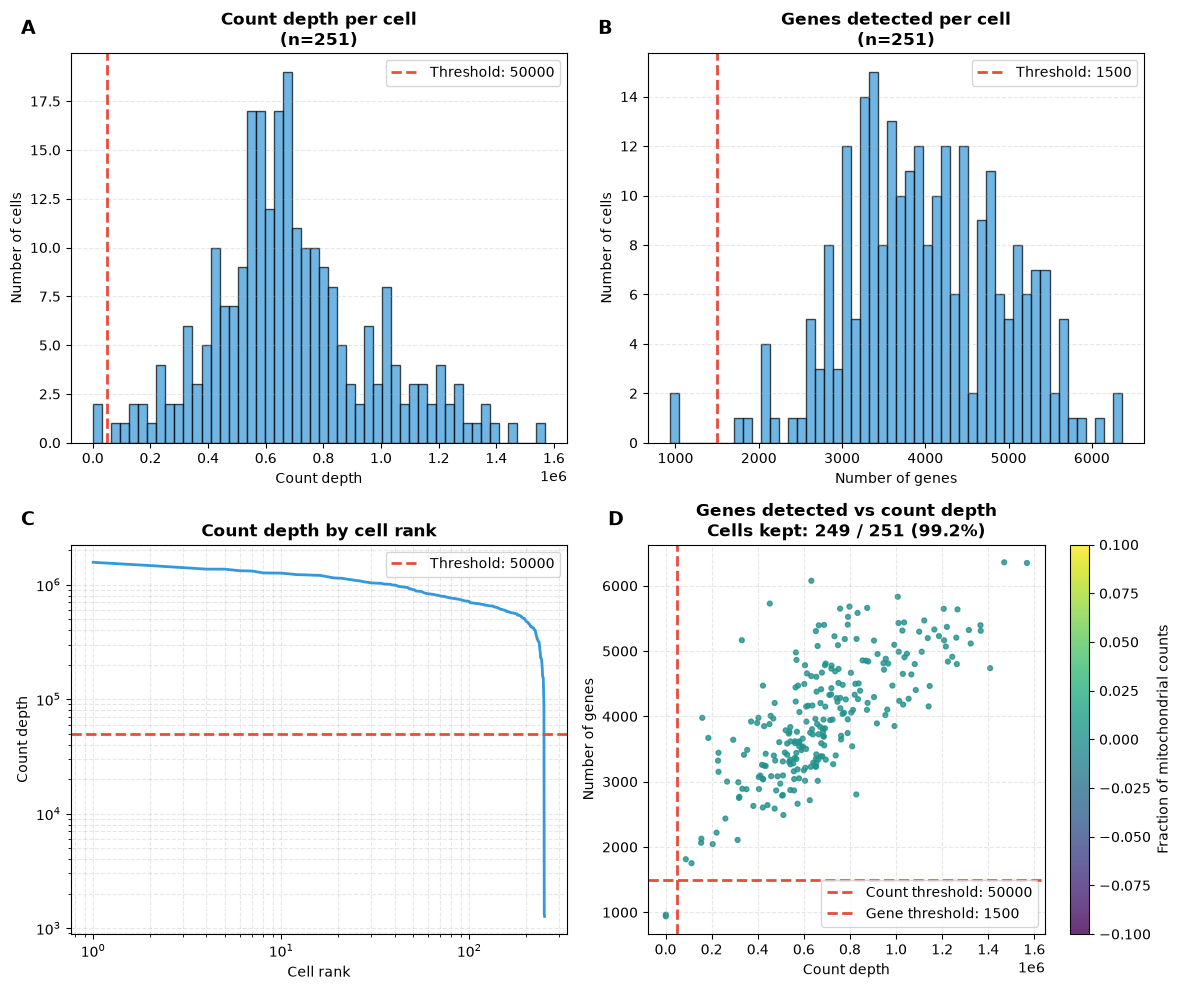

In [12]:
plot_qc_overview(
    raw_data,
    species=SPECIES,
    count_threshold=preprocessing_config.count_threshold,  # minimum count depth, set in the dataset config
    gene_threshold=preprocessing_config.gene_threshold,    # minimum genes per cell, set in the dataset config
)

## Mitochondrial, rRNA and apoptosis fractions

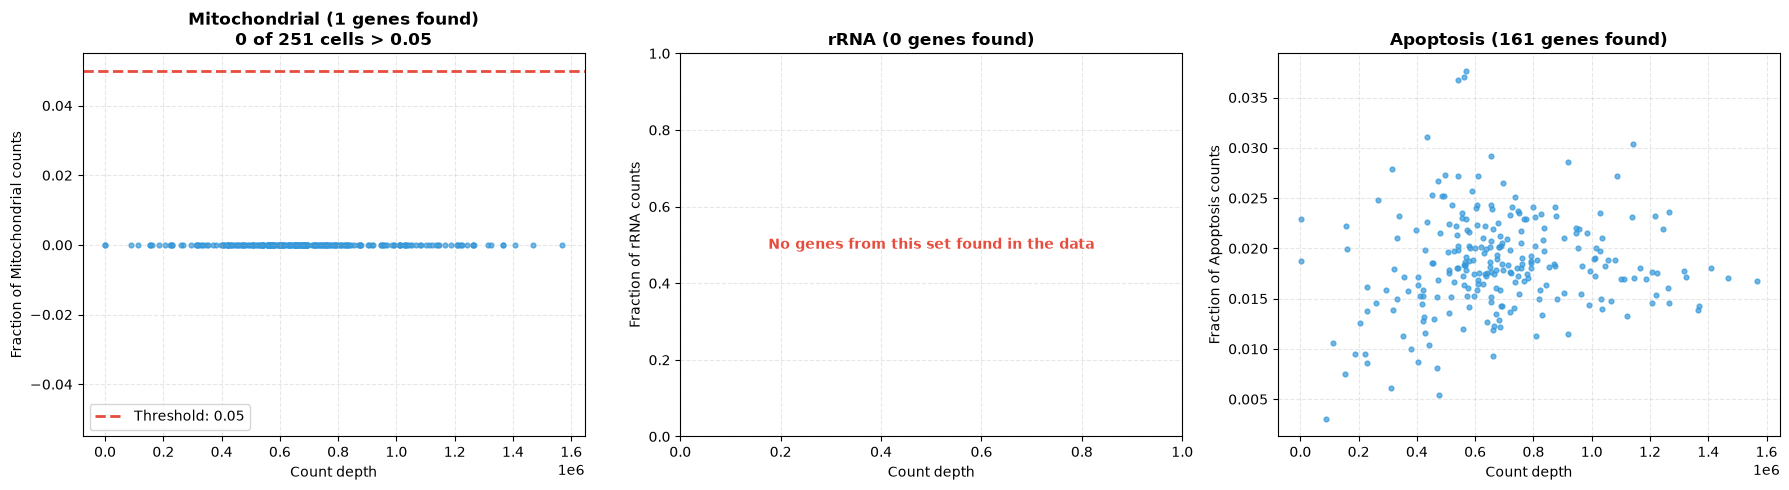

In [13]:
plot_gene_set_qc(raw_data, SPECIES, preprocessing_config)

## Genes

### Uniqueness

In [14]:
duplicates = duplicated_genes(raw_data)

print(f"Gene columns: {raw_data.shape[1]}, unique gene names: {raw_data.columns.nunique()}")
print(f"Gene names appearing in more than one column: {len(duplicates)}")
display(duplicates)

assert duplicates.empty, "Duplicated gene names found, see the table above"

Gene columns: 29863, unique gene names: 29863
Gene names appearing in more than one column: 0


,n_columns,identical_counts
gene,,


### Missing from the annotation

In [15]:
annotation = load_gene_annotation(SPECIES)
unmatched = unmatched_genes(raw_data, annotation)
alias_hits = unmatched.alias_matches
n_alias_genes = alias_hits["gene"].nunique()
n_ambiguous = alias_hits.loc[alias_hits["n_matches"] > 1, "gene"].nunique()

print(f"Genes matching no gene_id or gene_name: {n_alias_genes + len(unmatched.unknown_ensembl_ids) + len(unmatched.other)} / {raw_data.shape[1]}")
print(f"  found through alias_names: {n_alias_genes} ({n_ambiguous} matching more than one annotation row)")
print(f"  Ensembl IDs missing from the annotation: {len(unmatched.unknown_ensembl_ids)}, e.g. {unmatched.unknown_ensembl_ids[:5]}")
print(f"  other: {len(unmatched.other)}, e.g. {unmatched.other[:5]}")
display(alias_hits)

Genes matching no gene_id or gene_name: 12057 / 29863
  found through alias_names: 1 (0 matching more than one annotation row)
  Ensembl IDs missing from the annotation: 8, e.g. ['ENSMUSG00000054427', 'ENSMUSG00000068790', 'ENSMUSG00000073540', 'ENSMUSG00000073777', 'ENSMUSG00000076818']
  other: 12048, e.g. ['0610007C21Rik', '0610007L01Rik', '0610007P08Rik', '0610007P14Rik', '0610007P22Rik']


,gene,n_matches,gene_id,gene_name,gene_biotype,chromosome,MT_status,RB_status,TF_status,APOPT_status,alias_names
0,1700001J11Rik,1,ENSMUSG00000121668,Gm65991,protein_coding,9,NO_MT,NO_RB,NO_TF,NO_APOPT,1700001J11Rik


### rRNA

In [16]:
# Same matching as filter_rrna_genes, so these are exactly the columns the pipeline drops
rrna_columns = matching_genes(raw_data, rrna_genes(SPECIES, annotation))
rrna_counts = raw_data[rrna_columns].sum().sort_values(ascending=False).rename("total_counts")

print(f"rRNA genes filtered out: {len(rrna_columns)} / {raw_data.shape[1]}")
print(f"  share of all counts: {rrna_counts.sum() / raw_data.values.sum():.3f}")
display(rrna_counts.to_frame())

rRNA genes filtered out: 0 / 29863
  share of all counts: 0.000


,total_counts


## Filtering pipeline

In [17]:
clean_data = run_filtering_pipeline(raw_data, config=preprocessing_config, species=SPECIES)

clean_data.shape

(249, 14522)

### Low expression genes

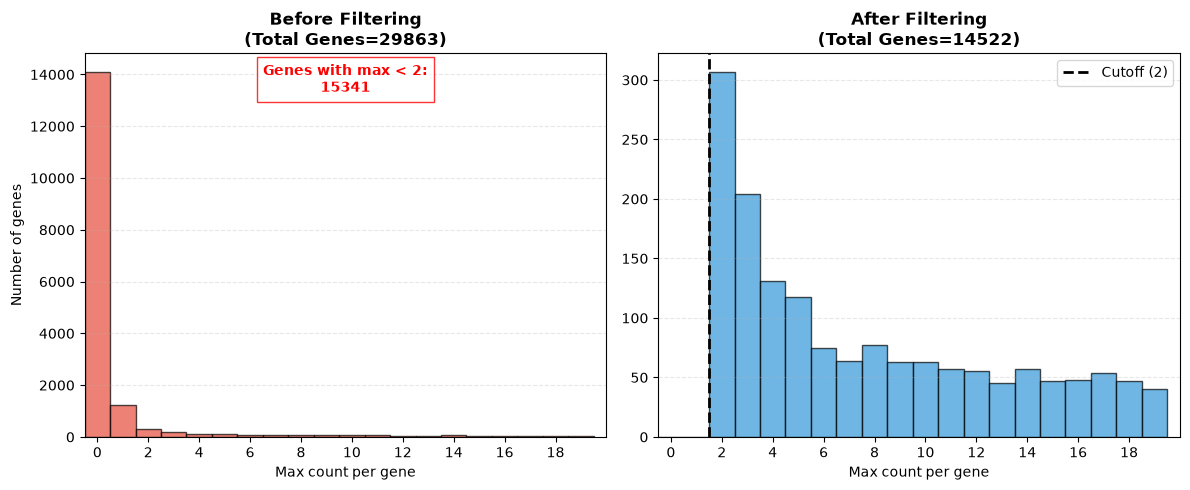

In [18]:
plot_gene_max_count_distribution(raw_data, clean_data, x_limit=20)

## Doublets (demonstration only)

We run the doublet filter to show how many cells it would remove, but the rest of the notebook continues from `clean_data`.

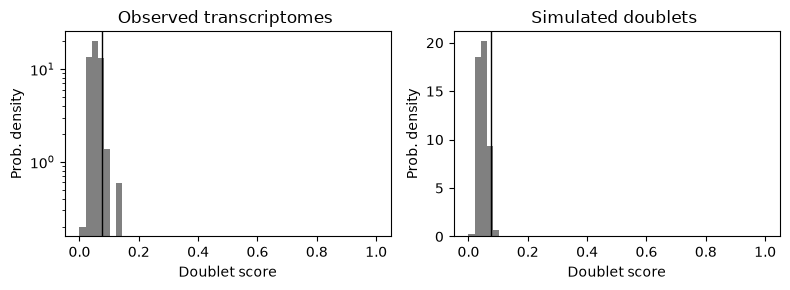

Cells removed as doublets: 38 / 249


In [19]:
# For demonstration only: the rest of the notebook continues from clean_data, not from no_doublets_data
no_doublets_data = filter_doublets(clean_data)

print(f"Cells removed as doublets: {clean_data.shape[0] - no_doublets_data.shape[0]} / {clean_data.shape[0]}")

# Normalization

## logCPM

### Normalize by library size

In [20]:
normalized_data = normalize_by_library_size(clean_data)

normalized_data.shape

(249, 14522)

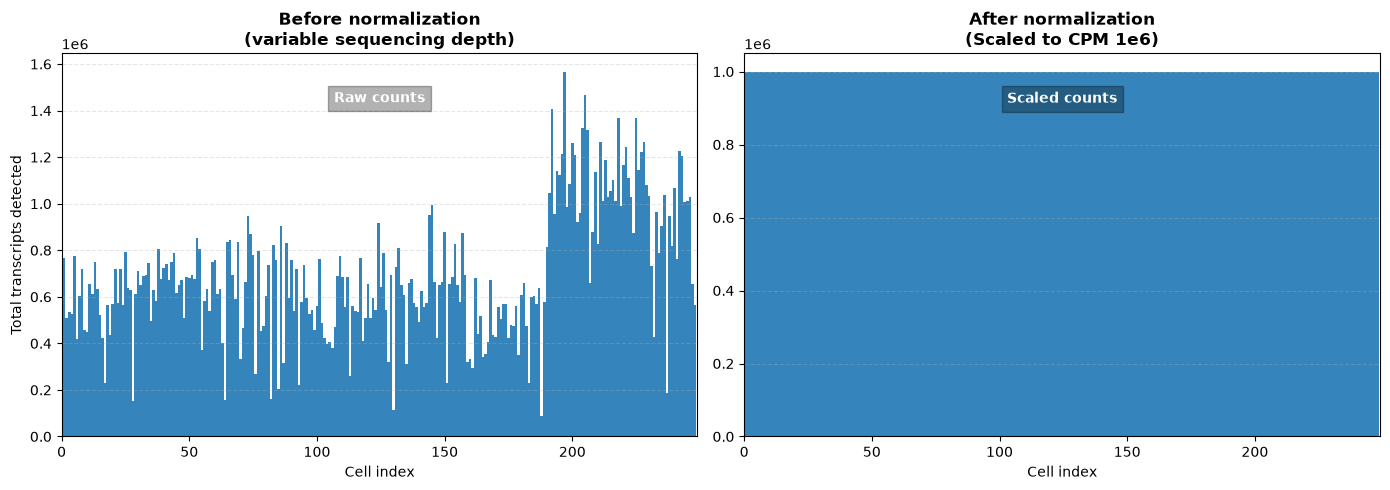

In [21]:
plot_normalization_comparison(clean_data, normalized_data, n_cells=normalized_data.shape[0])

### Log Transform

In [22]:
logged_data = log_transform(normalized_data)

logged_data.shape

(249, 14522)

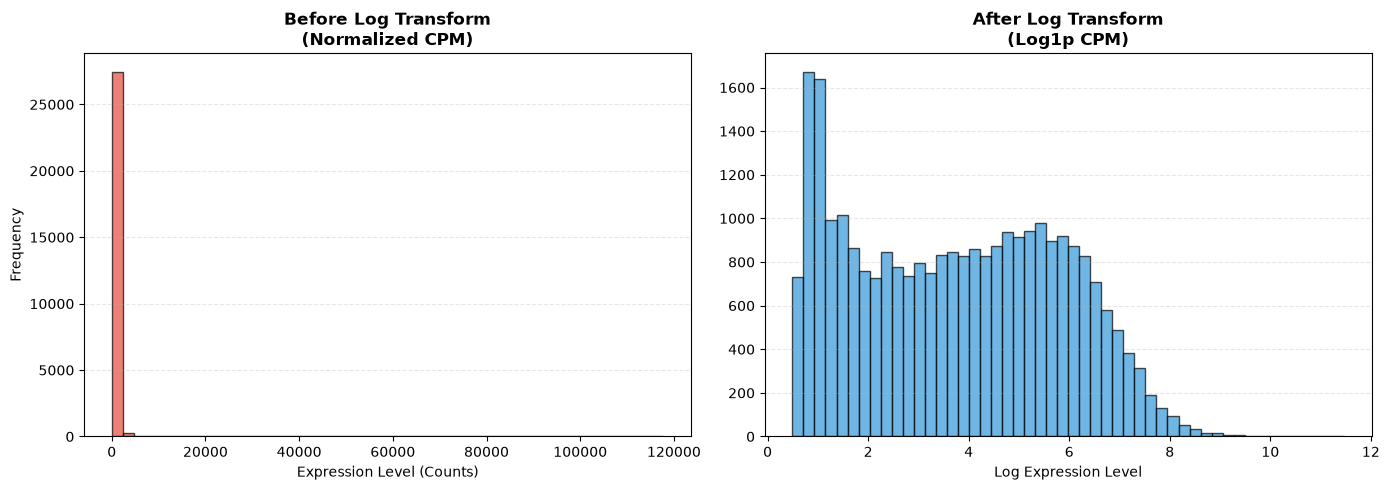

In [23]:
plot_log_transform_comparison(normalized_data, logged_data)

## Pearson residuals

In [24]:
pearsons_data = normalize_with_pearson(clean_data)

pearsons_data.shape

(249, 14522)

In [25]:
pearsons_data.head()

,0610007C21Rik,0610007L01Rik,0610007P08Rik,0610007P14Rik,0610007P22Rik,0610009B22Rik,0610009D07Rik,0610009O20Rik,0610010F05Rik,0610010K14Rik,...,rp9,scmh1,slc43a2,sr528,tsec-1,tspan-3,wdp103,wdr4,wiz,zap
cell_id,,,,,,,,,,,,,,,,,,,,,
GSM1488302,-1.679319,15.779734,-5.081990,-5.898495,-1.783768,-4.526008,0.738978,-4.132167,-0.940747,6.061339,...,-2.496965,-0.231756,-1.207613,-5.019352,-1.121255,-0.449609,-0.157470,-0.090923,-0.901029,-2.913565
GSM1488303,1.045913,-7.020617,-5.220899,-4.565715,-1.848225,-3.650744,5.244734,-4.066858,-0.975593,-4.590462,...,-3.740408,-0.240417,-1.252071,-2.995139,-1.162623,-0.466384,-0.163356,-0.094322,-0.934430,-3.012779
GSM1488304,-1.423415,-6.257682,4.705555,15.779734,-1.512741,-3.938415,-7.148553,-3.577130,-0.795165,-4.455750,...,-3.036424,-0.195657,-1.021578,-4.534205,-0.948248,-0.379658,-0.132937,-0.076756,-0.761514,-2.490114
GSM1488305,-1.458704,-6.258787,-4.548512,-6.137343,-1.550141,-4.022184,-7.241037,-3.655741,-0.815170,15.779734,...,-3.380117,-0.200610,-1.047168,8.293969,-0.972037,-0.389258,-0.136303,-0.078699,-0.780682,-2.549124
GSM1488306,-1.449039,-2.061580,-4.524044,-6.209468,-1.539898,-3.999327,12.571871,-3.634276,-0.809689,-5.115180,...,-2.039650,-0.199253,-1.040157,-4.600050,-0.965520,-0.386628,-0.135380,-0.078167,-0.775430,-2.532981
